# Industrial Energy Forecasting — Frozen Test Evaluation
**Member 5 contribution | Feng**

This notebook evaluates the frozen models from `03_model_development.ipynb` on the untouched chronological test period. No feature selection, hyperparameter tuning, or refitting is performed here. The exact 14 features and three benchmark definitions are loaded from `outputs/models/frozen_config.json` and `outputs/features/feature_list.json`.

## 1. Load the frozen protocol and test rows

The test set is selected strictly with `split == 'test'`. Assertions verify the expected row count, date boundaries, feature availability, and absence of duplicate target timestamps.

In [1]:
from pathlib import Path
import json
import platform

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'all_datasets' / 'steel_features.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Could not locate all_datasets/steel_features.csv.')
MODEL_DIR = ROOT / 'outputs' / 'models'
FEATURE_DIR = ROOT / 'outputs' / 'features'
FIGURE_DIR = ROOT / 'outputs' / 'figures'

frozen = json.loads((MODEL_DIR / 'frozen_config.json').read_text())
feature_info = json.loads((FEATURE_DIR / 'feature_list.json').read_text())
FEATURES = frozen['features']
TARGET = frozen['target']
BENCHMARKS = feature_info['benchmarks']
expected_test = 5_184

data = pd.read_csv(ROOT / 'all_datasets' / 'steel_features.csv', parse_dates=['date', 'origin'])
test = data.loc[data['split'].eq('test')].copy().reset_index(drop=True)
required = FEATURES + [TARGET, *BENCHMARKS.values(), 'analysis_load_type', 'date', 'origin']
missing = sorted(set(required) - set(test.columns))
if missing:
    raise KeyError(f'Missing required test columns: {missing}')
assert len(test) == expected_test, f'Expected {expected_test} test rows, got {len(test)}.'
assert test['date'].is_monotonic_increasing
assert not test['date'].duplicated().any()
assert test[FEATURES + [TARGET, *BENCHMARKS.values()]].notna().all().all()
print(f'Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}')
print(f'Test rows: {len(test):,} | {test.date.min()} to {test.date.max()}')
print(f'Frozen model: {frozen["selected_final_model"]} | features: {len(FEATURES)}')

Python 3.14.2 | pandas 3.1.1 | scikit-learn 1.9.1
Test rows: 5,184 | 2018-11-08 00:15:00 to 2019-01-01 00:00:00
Frozen model: Gradient Boosting | features: 14


## 2. Predict with frozen models and score the test period

All three saved models are scored on the same rows. The selected Gradient Boosting model is reported separately from the model comparison, while the benchmarks are calculated from their precomputed, target-aligned columns.

In [2]:
model_paths = frozen['model_files']
predictions = {}
for model_name, relative_path in model_paths.items():
    model = joblib.load(ROOT / relative_path)
    predictions[model_name] = np.asarray(model.predict(test[FEATURES]), dtype=float)

predictions.update({
    name: test[column].to_numpy(dtype=float)
    for name, column in BENCHMARKS.items()
})
actual = test[TARGET].to_numpy(dtype=float)

def score(name, values):
    errors = actual - values
    return {
        'model': name,
        'kind': 'benchmark' if name in BENCHMARKS else 'machine learning',
        'MAE': mean_absolute_error(actual, values),
        'RMSE': np.sqrt(mean_squared_error(actual, values)),
        'R2': r2_score(actual, values),
        'P95_AE': np.percentile(np.abs(errors), 95),
        'mean_error_actual_minus_forecast': errors.mean(),
    }

test_metrics = pd.DataFrame([score(name, values) for name, values in predictions.items()])
persistence_rmse = test_metrics.loc[test_metrics.model.eq('Persistence'), 'RMSE'].iloc[0]
test_metrics['RMSE_vs_persistence_pct'] = 100 * (test_metrics['RMSE'] / persistence_rmse - 1)
test_metrics = test_metrics.sort_values('RMSE').reset_index(drop=True)
display(test_metrics.round(4))
test_metrics.to_csv(MODEL_DIR / 'test_evaluation_metrics.csv', index=False)

selected = frozen['selected_final_model']
selected_row = test_metrics.loc[test_metrics.model.eq(selected)].iloc[0]
print(f'\nSelected model: {selected}')
print(f'Test RMSE: {selected_row.RMSE:.3f} kWh | test MAE: {selected_row.MAE:.3f} kWh | test R²: {selected_row.R2:.3f}')

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator OneHotEncoder from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator ColumnTransformer from version 1.9.0 when using version

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator RandomForestRegressor from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DummyRegressor from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeRegressor from version 1.9.0 when u

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator GradientBoostingRegressor from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


,model,kind,MAE,RMSE,R2,P95_AE,mean_error_actual_minus_forecast,RMSE_vs_persistence_pct
0,Gradient Boosting,machine learning,3.7233,7.7649,0.9382,17.9998,-0.3556,-33.1032
1,Random Forest,machine learning,3.6783,7.7824,0.9379,17.9825,-0.3039,-32.9526
2,Linear Regression,machine learning,6.5192,10.4512,0.8880,22.0690,-1.2144,-9.9599
3,Persistence,benchmark,4.9698,11.6073,0.8618,27.5000,0.0007,0.0000
4,Weekly seasonal,benchmark,12.7464,24.3368,0.3926,59.1780,-2.1416,109.6680
5,Daily seasonal,benchmark,14.5401,26.9236,0.2566,62.7755,-0.4439,131.9537



Selected model: Gradient Boosting
Test RMSE: 7.765 kWh | test MAE: 3.723 kWh | test R²: 0.938


## 3. Validation-to-test generalisation check

Validation values are read from the frozen configuration rather than recomputed or used for tuning. The comparison quantifies the change in RMSE and MAE after moving to the untouched November–December test period.

In [3]:
validation = frozen['validation_metrics']
comparison = []
for name in predictions:
    val = validation[name]
    row = test_metrics.loc[test_metrics.model.eq(name)].iloc[0]
    comparison.append({
        'model': name,
        'validation_MAE': val['MAE'],
        'test_MAE': row['MAE'],
        'MAE_change': row['MAE'] - val['MAE'],
        'validation_RMSE': val['RMSE'],
        'test_RMSE': row['RMSE'],
        'RMSE_change': row['RMSE'] - val['RMSE'],
        'validation_R2': val['R2'],
        'test_R2': row['R2'],
        'R2_change': row['R2'] - val['R2'],
    })
validation_test = pd.DataFrame(comparison)
display(validation_test.round(4))
validation_test.to_csv(MODEL_DIR / 'validation_test_comparison.csv', index=False)
assert set(validation_test.model) == set(predictions)
print('No test result was used to alter a model, feature, or hyperparameter.')

,model,validation_MAE,test_MAE,MAE_change,validation_RMSE,test_RMSE,RMSE_change,validation_R2,test_R2,R2_change
0,Linear Regression,6.5714,6.5192,-0.0522,11.1910,10.4512,-0.7398,0.8678,0.8880,0.0202
1,Random Forest,4.0281,3.6783,-0.3498,8.8435,7.7824,-1.0611,0.9174,0.9379,0.0205
2,Gradient Boosting,4.1312,3.7233,-0.4079,8.7747,7.7649,-1.0098,0.9187,0.9382,0.0195
3,Persistence,5.7558,4.9698,-0.7860,12.7014,11.6073,-1.0941,0.8297,0.8618,0.0321
4,Daily seasonal,15.2834,14.5401,-0.7433,28.9065,26.9236,-1.9829,0.1177,0.2566,0.1389
5,Weekly seasonal,13.0323,12.7464,-0.2859,25.0649,24.3368,-0.7281,0.3366,0.3926,0.0560


No test result was used to alter a model, feature, or hyperparameter.


## 4. Test residual diagnostics by operating regime and hour

`analysis_load_type` is used only for post-hoc grouping, consistent with the feature-engineering handover. The tables expose whether validation error patterns persist in the held-out period.

,analysis_load_type,intervals,MAE,RMSE,P95_AE,mean_error_actual_minus_forecast
0,Light_Load,2832.0,1.2465,3.8393,6.1353,-0.2701
1,Medium_Load,1344.0,7.2102,11.2981,24.9027,-0.0655
2,Maximum_Load,1008.0,6.0327,9.9234,21.8909,-0.9826


,hour,intervals,MAE,RMSE,P95_AE,mean_error_actual_minus_forecast
0,0,216.0,0.3454,0.6958,1.1316,0.1030
1,1,216.0,0.4468,2.0835,1.0789,0.0531
2,2,216.0,0.2921,0.4548,1.1006,0.1467
3,3,216.0,0.2556,0.3902,0.8767,0.0112
4,4,216.0,0.2802,0.4191,0.8194,-0.1109
5,5,216.0,0.3235,0.5251,1.1007,-0.1544
6,6,216.0,0.3454,0.5662,1.1139,-0.1463
7,7,216.0,0.5001,0.7936,1.5790,-0.0888
8,8,216.0,7.7825,11.1556,23.1909,-2.5602
9,9,216.0,7.8062,11.6350,27.9031,1.1896


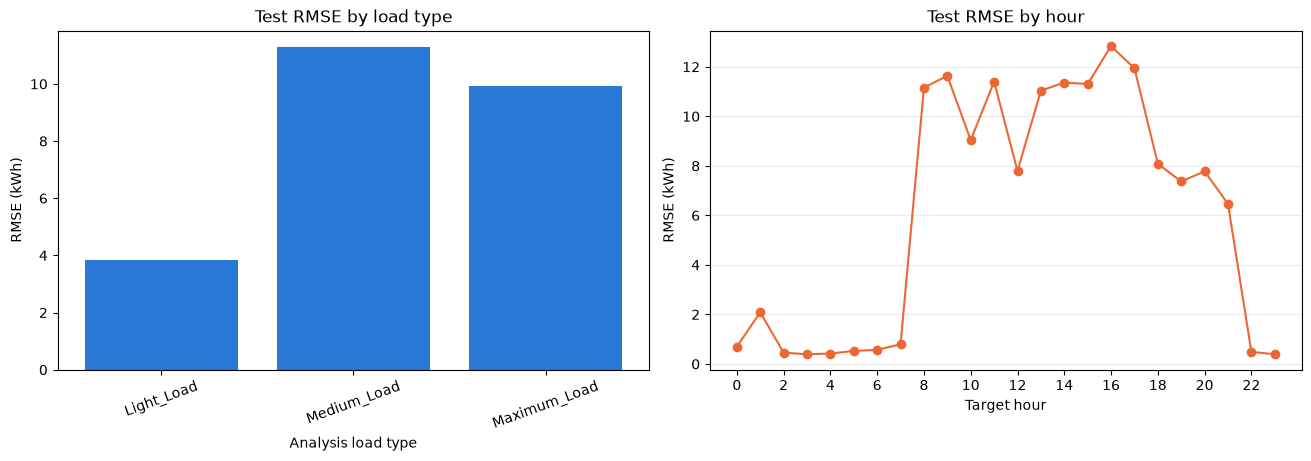

Diagnostics saved to /workspaces/ML-Assignment/outputs/models and /workspaces/ML-Assignment/outputs/figures.


In [4]:
diagnostic = test[['date', 'analysis_load_type', 'hour']].copy()
diagnostic['actual'] = actual
diagnostic['forecast'] = predictions[selected]
diagnostic['error'] = diagnostic['actual'] - diagnostic['forecast']
diagnostic['absolute_error'] = diagnostic['error'].abs()
diagnostic['squared_error'] = diagnostic['error'].pow(2)

def grouped_scores(group):
    return pd.Series({
        'intervals': len(group),
        'MAE': group.absolute_error.mean(),
        'RMSE': np.sqrt(group.squared_error.mean()),
        'P95_AE': group.absolute_error.quantile(0.95),
        'mean_error_actual_minus_forecast': group.error.mean(),
    })

by_load_type = diagnostic.groupby('analysis_load_type', sort=False).apply(grouped_scores, include_groups=False).reset_index()
by_hour = diagnostic.groupby('hour', sort=True).apply(grouped_scores, include_groups=False).reset_index()
display(by_load_type.round(4))
display(by_hour.round(4))
by_load_type.to_csv(MODEL_DIR / 'test_error_by_load_type.csv', index=False)
by_hour.to_csv(MODEL_DIR / 'test_error_by_hour.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
axes[0].bar(by_load_type['analysis_load_type'], by_load_type['RMSE'], color='#2a78d6')
axes[0].set(title='Test RMSE by load type', xlabel='Analysis load type', ylabel='RMSE (kWh)')
axes[0].tick_params(axis='x', rotation=20)
axes[1].plot(by_hour['hour'], by_hour['RMSE'], marker='o', color='#eb6834')
axes[1].set(title='Test RMSE by hour', xlabel='Target hour', ylabel='RMSE (kWh)')
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(axis='y', alpha=0.25)
fig.savefig(FIGURE_DIR / 'mt_test_error_diagnostics.png', dpi=160)
plt.show()
print(f'Diagnostics saved to {MODEL_DIR} and {FIGURE_DIR}.')

## 5. Additional held-out-test diagnostics

These descriptive plots and tables assess stability and error shape on the same untouched test set. They do not change the frozen model or its selection.

,month,intervals,MAE,RMSE,P95_AE,mean_error_actual_minus_forecast
0,2018-11,2207.0,4.6353,9.1398,20.8695,0.0571
1,2018-12,2976.0,3.0482,6.5634,14.7124,-0.6619
2,2019-01,1.0,0.0689,0.0689,0.0689,0.0689


,definition,cutoff_kwh,intervals,MAE,RMSE,mean_error_actual_minus_forecast
0,actual >= test-set 90th percentile,69.3,520,13.3718,17.1228,7.8469


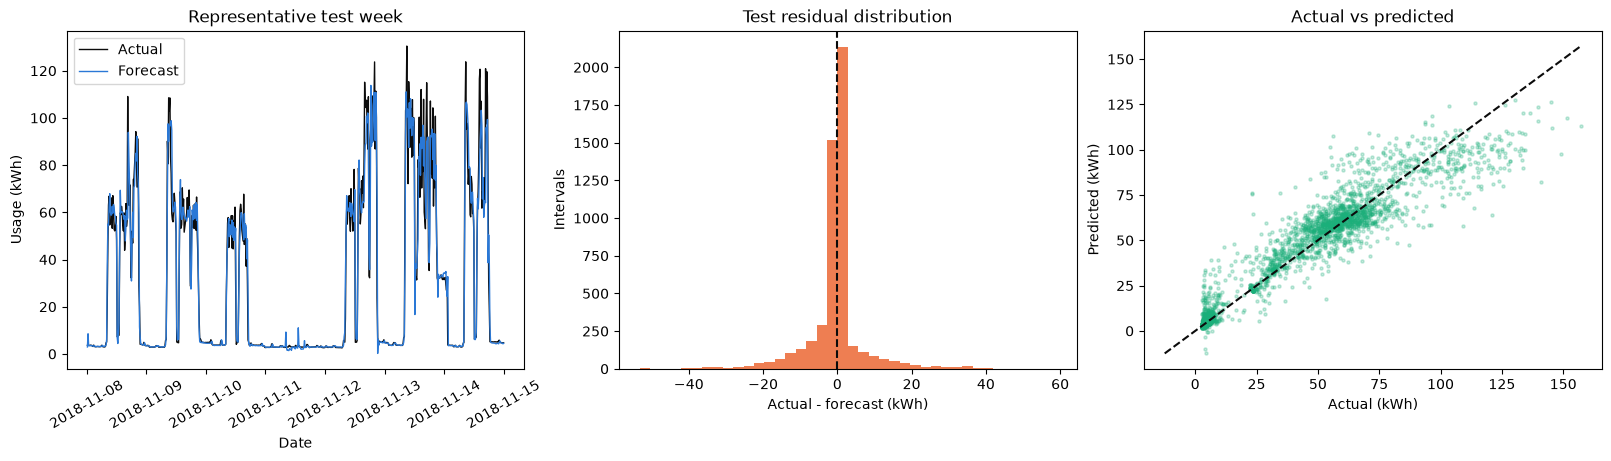

Extended diagnostics saved to /workspaces/ML-Assignment/outputs/models and /workspaces/ML-Assignment/outputs/figures.


In [5]:
diagnostic['month'] = diagnostic['date'].dt.to_period('M').astype(str)
monthly = diagnostic.groupby('month', sort=True).apply(grouped_scores, include_groups=False).reset_index()
display(monthly.round(4))
monthly.to_csv(MODEL_DIR / 'test_error_by_month.csv', index=False)

peak_cutoff = actual >= np.quantile(actual, 0.90)
peak_errors = diagnostic.loc[peak_cutoff].copy()
peak_summary = pd.DataFrame([{
    'definition': 'actual >= test-set 90th percentile',
    'cutoff_kwh': np.quantile(actual, 0.90),
    'intervals': len(peak_errors),
    'MAE': peak_errors['absolute_error'].mean(),
    'RMSE': np.sqrt(peak_errors['squared_error'].mean()),
    'mean_error_actual_minus_forecast': peak_errors['error'].mean(),
}])
display(peak_summary.round(4))
peak_summary.to_csv(MODEL_DIR / 'test_peak_error_summary.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
week = diagnostic.iloc[:7 * 96]
axes[0].plot(week['date'], week['actual'], label='Actual', color='#0b0b0b', linewidth=1)
axes[0].plot(week['date'], week['forecast'], label='Forecast', color='#2a78d6', linewidth=1)
axes[0].set(title='Representative test week', xlabel='Date', ylabel='Usage (kWh)')
axes[0].legend()
axes[0].tick_params(axis='x', rotation=30)
axes[1].hist(diagnostic['error'], bins=40, color='#eb6834', alpha=0.85)
axes[1].axvline(0, color='#0b0b0b', linestyle='--')
axes[1].set(title='Test residual distribution', xlabel='Actual - forecast (kWh)', ylabel='Intervals')
axes[2].scatter(actual, predictions[selected], s=5, alpha=0.25, color='#1baf7a')
limits = [min(actual.min(), predictions[selected].min()), max(actual.max(), predictions[selected].max())]
axes[2].plot(limits, limits, color='#0b0b0b', linestyle='--')
axes[2].set(title='Actual vs predicted', xlabel='Actual (kWh)', ylabel='Predicted (kWh)')
fig.savefig(FIGURE_DIR / 'mt_test_extended_diagnostics.png', dpi=160)
plt.show()
print(f'Extended diagnostics saved to {MODEL_DIR} and {FIGURE_DIR}.')

## 6. Evaluation conclusion

The test tables above are the final unbiased comparison. The selected model remains the frozen Gradient Boosting configuration because selection was completed using validation RMSE before this notebook. Any difference between validation and test performance is reported as generalisation behavior, not used to retune the model.